# Double well with an exactly linear ratio

$$V(x)=\frac{x^4}{32}-\frac{x^2}{4},\qquad
\mu(x)=0.5x-0.125x^3,\qquad \sigma(x)=1-0.25x^2.$$

Since $\mu(x)=0.5x\,\sigma(x)$, we have $(\mu/\sigma)''=0$ for $-2<x<2$. The potential minima are $x=\pm2$. Diffusion vanishes at these minima, where the quotient is undefined. This differs from the original everywhere-positive diffusion. The simulated paths for seeds 3, 7 and 11 stay inside this interval.

Repeat the Black-Scholes workflow with $N=100000$, $T=1$, $X_0=1$, seed 3 and the same diffusion search. ODE2 receives the known initial drift $0.375$ and slope $0.125$. Each recovered drift supplies noise to a separate final SSISDE fit. No analytic diffusion derivatives are used for recovery.

The other coefficient trials and checks on seeds 7 and 11 are recorded alongside this notebook. The original notebook in the parent folder remains the baseline.

Compare three final SSISDE fits, using noise from Method 1, Method 2 and ODE2. Each fit uses the same degree-5 libraries, seven-fold cross-validation and seven elastic-net mixing values. The final table reports noise, drift and diffusion errors.


In [1]:
from pathlib import Path
import os
import sys

if not (3, 10) <= sys.version_info[:2] < (3, 13):
    raise RuntimeError("The original dependency pins require Python 3.10–3.12; use the local .venv or a compatible Colab runtime.")

def _find_project():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]:
        if (candidate / 'models/stochastic_sindy.py').is_file() and (candidate / 'requirements.txt').is_file():
            return candidate
    return None

PROJECT_ROOT = _find_project()
if PROJECT_ROOT is None:
    import importlib.util
    try:
        _in_colab = importlib.util.find_spec('google.colab') is not None
    except ModuleNotFoundError:
        _in_colab = False
    if not _in_colab:
        raise FileNotFoundError("Open this notebook from the SSISDE checkout so its Python scripts are available.")

    def _download_private_project():
        from getpass import getpass
        from io import BytesIO
        from urllib.request import Request, urlopen
        from zipfile import ZipFile
        token = getpass('GitHub token (read-only Contents access to SSISDE): ')
        try:
            request = Request(
                'https://api.github.com/repos/munawarali93/SSISDE/zipball/main',
                headers={'Authorization': f'Bearer {token}', 'Accept': 'application/vnd.github+json'},
            )
            with urlopen(request, timeout=120) as response:
                archive_bytes = response.read()
        finally:
            token = None
            request = None
        destination = Path('/content/SSISDE')
        with ZipFile(BytesIO(archive_bytes)) as archive:
            for member in archive.infolist():
                relative = Path(*Path(member.filename).parts[1:])
                if member.is_dir() or not relative.parts:
                    continue
                target = (destination / relative).resolve()
                if not target.is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(member))
        return destination

    PROJECT_ROOT = _download_private_project()

os.chdir(PROJECT_ROOT / 'experiments/double_well/coefficient_study')
print(f'Project: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')

sys.path.insert(0, str(PROJECT_ROOT))
RESULTS = PROJECT_ROOT / 'outputs/double_well/coefficient_study/matched_factor'
RESULTS.mkdir(parents=True, exist_ok=True)


Project: /Users/munawarali/Documents/GitHub/SSISDE
Python: 3.11.13


##Install libraries

In [2]:
# Install into the selected kernel before importing scientific libraries.
# The four original version pins are retained in requirements.txt.
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT_ROOT / 'requirements.txt')])



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


0

##Import libraries

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pysindy as ps
import random
import iisignature
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
import json
from threadpoolctl import threadpool_limits
from models.diffusion_tuning import fit_diffusion


Matplotlib is building the font cache; this may take a moment.


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


##Defining parameters and simulating noise

In [4]:
from data_generation.double_well import generate_data
N, T, S0, seed = 100000, 1.0, 1.0, 3
coefficients = dict(a=0.5, b=0.125, c=1.0, d=-0.25)
t, dt, S_, W_, mu_exact_, sigma_exact_ = generate_data(N, T, S0, seed, **coefficients)
fine_dt = dt


##Simulating primary processes

## $$dS_t = \mu(S_t)dt + \sigma(S_t)dB_t$$

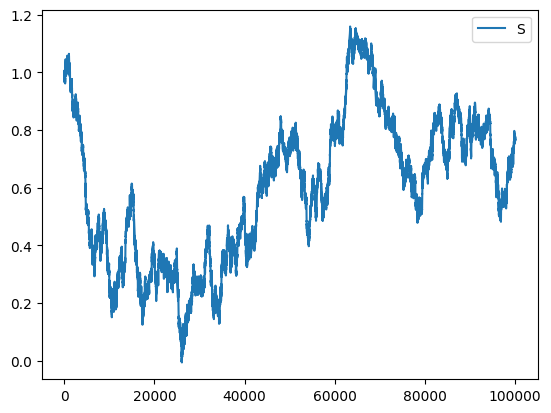

In [5]:
plt.plot(S_, label="S")
plt.legend()
plt.show()

##compute quadratic variation

  0%|          | 0/100000 [00:00<?, ?it/s]

 13%|█▎        | 13403/100000 [00:00<00:00, 134021.82it/s]

 27%|██▋       | 26806/100000 [00:00<00:00, 87687.57it/s] 

 36%|███▋      | 36478/100000 [00:00<00:00, 68284.30it/s]

 44%|████▍     | 44018/100000 [00:00<00:00, 57272.22it/s]

...

 92%|█████████▏| 92053/100000 [00:02<00:00, 22087.45it/s]

 94%|█████████▍| 94242/100000 [00:02<00:00, 21521.37it/s]

 96%|█████████▋| 96378/100000 [00:02<00:00, 20951.71it/s]

 98%|█████████▊| 98461/100000 [00:02<00:00, 20413.71it/s]

100%|██████████| 100000/100000 [00:02<00:00, 34388.91it/s]

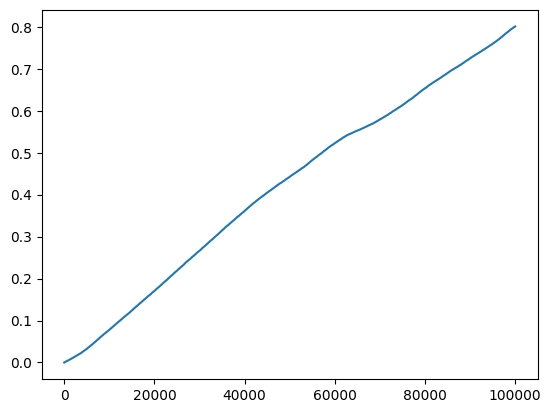

In [6]:
from models.quadratic_variation import estimate_quadratic_variation
QV, dQV, diff_method = estimate_quadratic_variation(S_, t)
plt.plot(QV)

## Approximating $\sigma$

Use the existing degree-4 variance library. Select SR3 settings on the last
20% of observations, then refit on the full path. The true diffusion is used
only to report error. All subsequent stages follow Black-Scholes.

In [7]:
thresholds = [0.01, 0.1, 0.3, 1.0, 3.0, 10.0]
nus = [0.1, 0.5, 2.0]
model, sigma_settings, sigma_search = fit_diffusion(S_, t, dQV, thresholds, nus)
sigma_equation = model.equations(precision=8)[0]
print('sigma^2(X) =', sigma_equation)
print(sigma_settings)
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))

sigma^2(X) = 0.98519395 1 + -0.45346107 X^2 + 0.02514860 X^4
{'threshold': 0.1, 'nu': 2.0, 'validation_mse': 0.896307212111755, 'max_iter': 10000, 'tol': 1e-08, 'terms': 3, 'converged': True, 'full_fit_converged': True}


3013

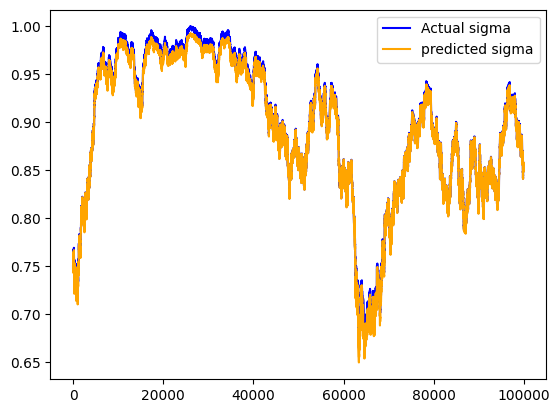

In [8]:
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_pred_ = np.array(sigma_pred_)
plt.plot(sigma_exact_, label="Actual sigma",color="blue")
plt.plot(sigma_pred_,label="predicted sigma", color="orange")
plt.legend()
plt.show()

In [9]:
from models.diffusion_derivatives import diffusion_derivatives
sigma_prime_, sigma_2prime_, sigma_3prime_ = diffusion_derivatives(sigma_pred_, S_, diff_method)


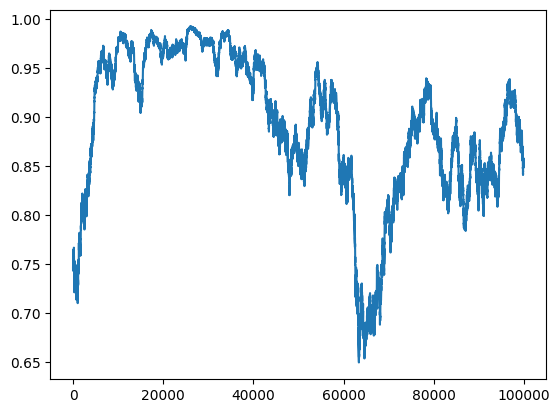

In [10]:
plt.plot(sigma_pred_)

##Q Brownian motion

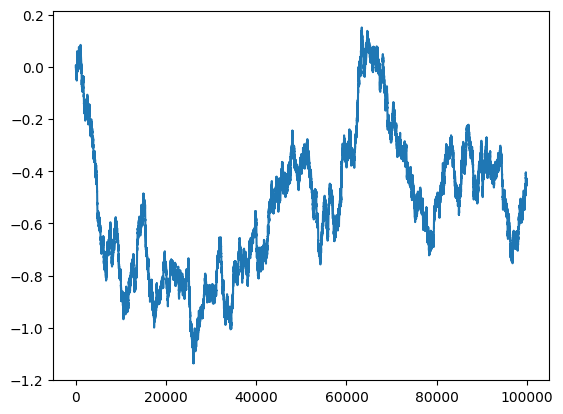

In [11]:
from models.q_brownian_motion import recover_q_noise
BQ_ = recover_q_noise(S_, sigma_pred_)
plt.plot(BQ_)

#Fit signature model

In [12]:
keep_cols = [0, 1, 3, 4, 5, 13]

  0%|          | 0/1000 [00:00<?, ?it/s]

 19%|█▉        | 194/1000 [00:00<00:00, 1935.82it/s]

 39%|███▉      | 388/1000 [00:00<00:00, 1938.04it/s]

 58%|█████▊    | 583/1000 [00:00<00:00, 1943.09it/s]

 78%|███████▊  | 781/1000 [00:00<00:00, 1954.63it/s]

 98%|█████████▊| 977/1000 [00:00<00:00, 1920.09it/s]

100%|██████████| 1000/1000 [00:00<00:00, 1924.55it/s]

0.0001007300519090524

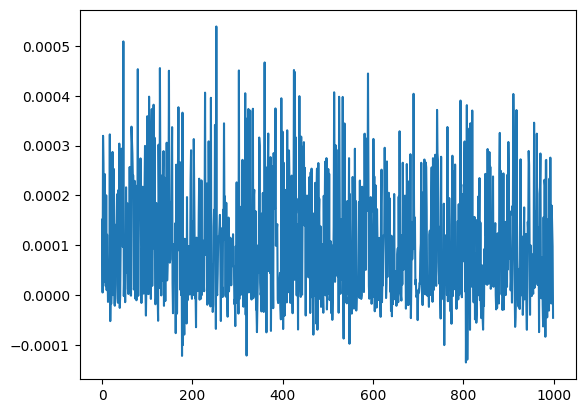

In [13]:
from models.signature_regression import fit_signature
M = 100
K = int(N/M)
l21 = fit_signature(S_, BQ_, t, keep_cols, M)
plt.plot(l21)
np.mean(l21)

In [14]:
from data_generation.coarse_graining import coarse_grain
sigma_pred, mu_exact, S, BQ, W, sigma_exact = coarse_grain(
    S_, BQ_, W_, mu_exact_, sigma_exact_, sigma_pred_, M, K,
)


In [15]:
from models.coarse_diffusion_derivatives import coarse_diffusion_derivatives
sigma_prime, sigma_2prime, sigma_3prime = coarse_diffusion_derivatives(sigma_pred, S, diff_method)


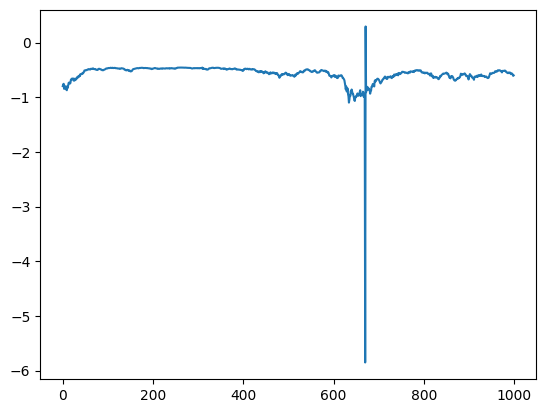

In [16]:
plt.plot(sigma_2prime)

## Predicting $\mu(X_t)$ by tuncating up to level-2 of iterated integrals

In [17]:
from models.drift_coefficients import drift_coefficients
mu_0, a, b, b_ = drift_coefficients(mu_exact, sigma_pred, sigma_prime, sigma_2prime, l21)


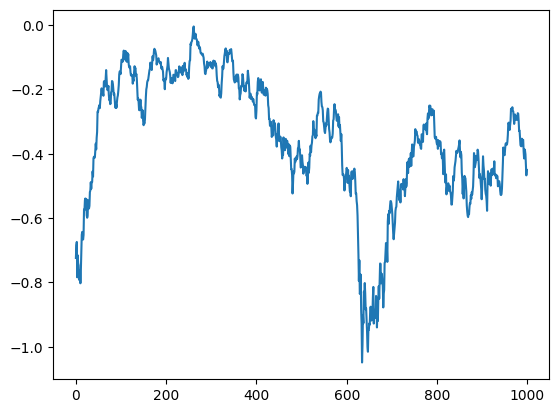

In [18]:
#plt.plot(b)
plt.plot(a)

In [19]:
from models.drift_recovery import recover_drift
mu_pred1, mu_pred2 = recover_drift(S, a, b, b_, mu_0)


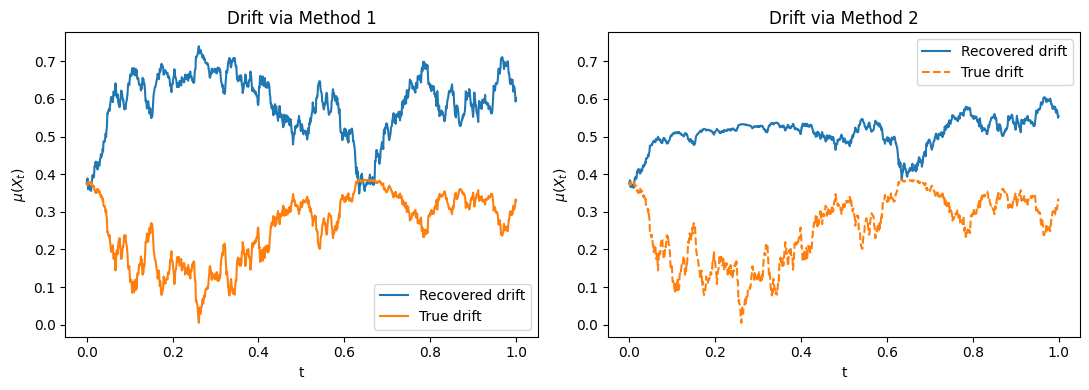

In [20]:
t_ = np.linspace(0, T, K)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_, mu_pred1, label="Recovered drift")
axes[0].plot(t_, mu_exact, label="True drift")
axes[0].set_title("Drift via Method 1")
axes[0].set_xlabel("t")
axes[0].set_ylabel("$\mu(X_t)$")
axes[0].legend()
axes[1].plot(t_, mu_pred2, label="Recovered drift")
axes[1].set_title("Drift via Method 2")
axes[1].plot(t_, mu_exact, '--', label="True drift")
axes[1].set_xlabel("t")
axes[1].set_ylabel("$\mu(X_t)$")
axes[1].legend()
axes[1].set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.savefig("matched_factor_Drift_via_Euler.png", bbox_inches='tight', dpi=300)
plt.show()

## Drift recovery from ODE2

Use the same ODE2 recurrence as Black-Scholes. Supply the initial drift and
the known initial spatial slope for this process. This is a drift comparison;
noise recovery below uses Method 1.

In [21]:
lambda_0 = coefficients['a'] - 3*coefficients['b']*S0**2
from models.drift_recovery_from_ODE2 import recover_drift_ode2
mu_pred11, lamda_pred = recover_drift_ode2(S, sigma_pred, sigma_prime, sigma_2prime, mu_0, lambda_0)


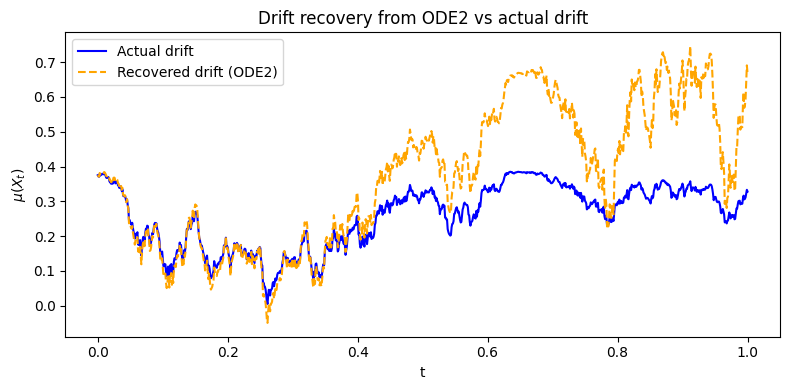

ODE2 drift MSE: 0.0270114
ODE2 drift RMSE: 0.164352


In [22]:
plt.figure(figsize=(8, 4))
plt.plot(t_, mu_exact, label="Actual drift", color="blue")
plt.plot(t_, mu_pred11, '--', label="Recovered drift (ODE2)", color="orange")
plt.xlabel("t")
plt.ylabel(r"$\mu(X_t)$")
plt.title("Drift recovery from ODE2 vs actual drift")
plt.legend()
plt.tight_layout()
plt.savefig("matched_factor_Drift_via_ODE2.png", bbox_inches='tight', dpi=300)
plt.show()

ode2_drift_mse = mean_squared_error(mu_exact, mu_pred11)
print(f"ODE2 drift MSE: {ode2_drift_mse:.6g}")
print(f"ODE2 drift RMSE: {np.sqrt(ode2_drift_mse):.6g}")


## Drift comparison across all methods

Method 1: drift RMSE = 0.369346
Method 2: drift RMSE = 0.276361
ODE2: drift RMSE = 0.164352


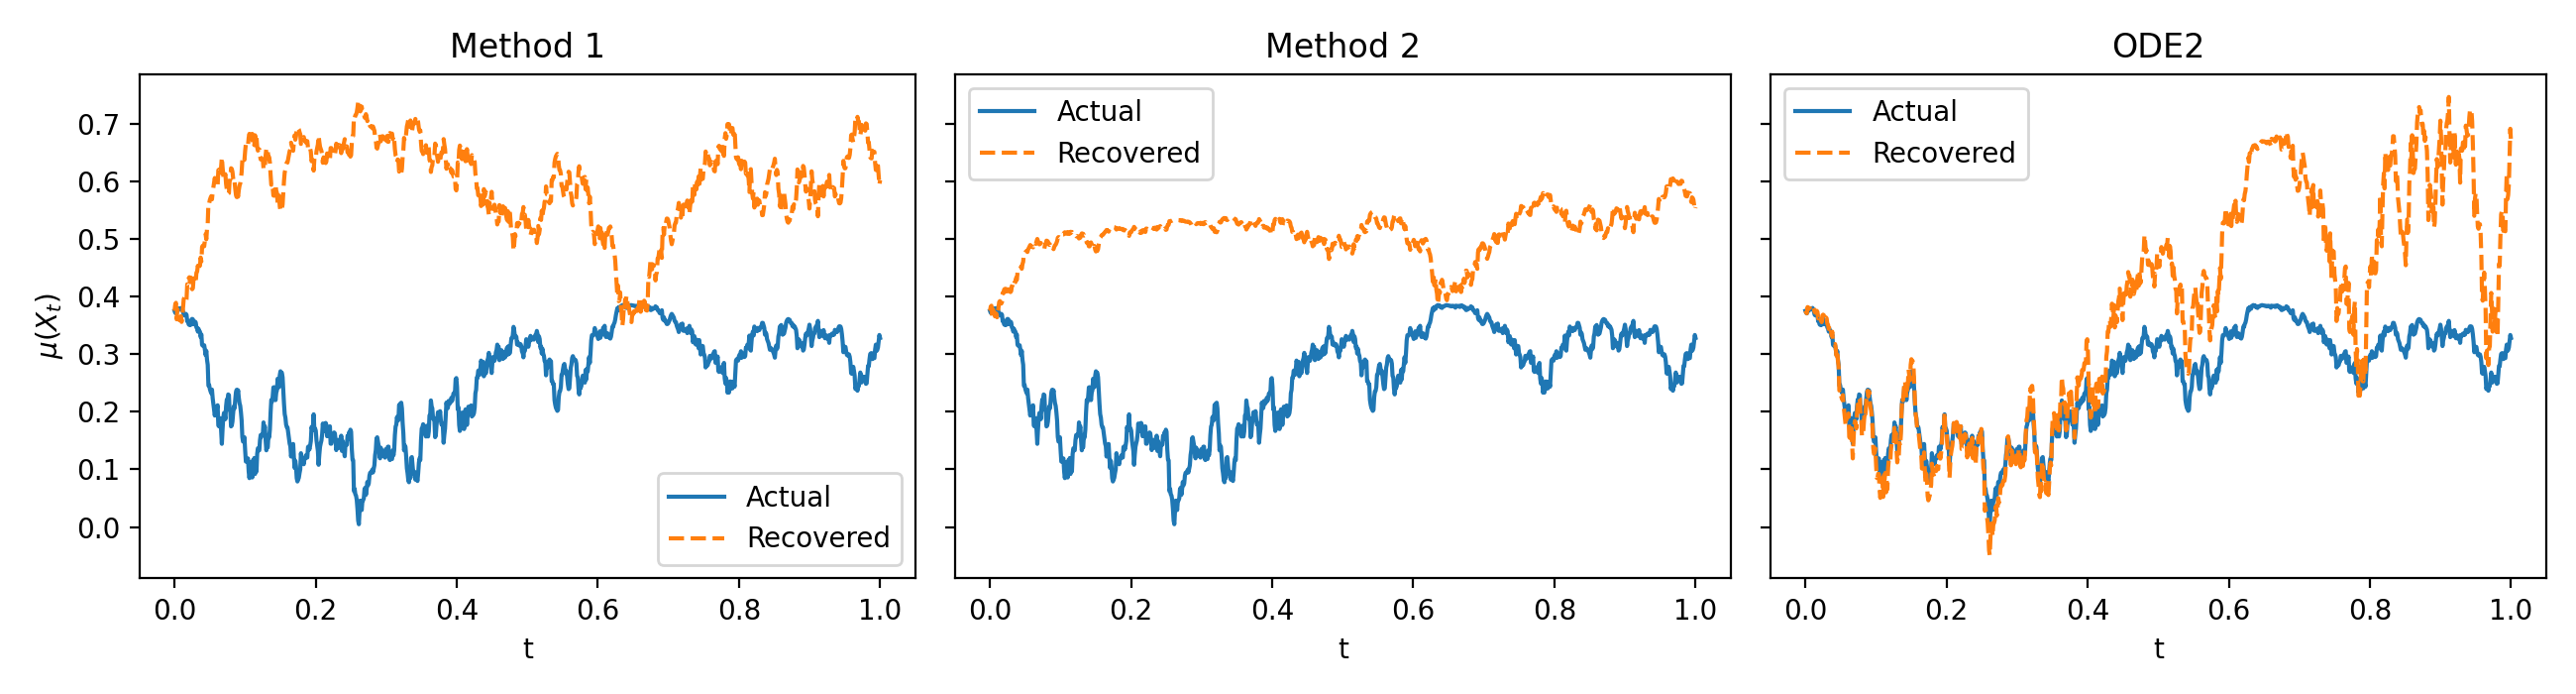

In [ ]:
t_ = np.linspace(0, T, K)
drift_estimates = {'Method 1': mu_pred1, 'Method 2': mu_pred2, 'ODE2': mu_pred11}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, estimate) in zip(axes, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
    print(f"{name}: drift RMSE = {drift_rmse[name]:.6g}")
axes[0].set_ylabel(r'$\mu(X_t)$')
fig.tight_layout()
fig.savefig('drift_comparison_linear_ratio.png', dpi=200)
plt.show()


##Predicting P-Brownian motion

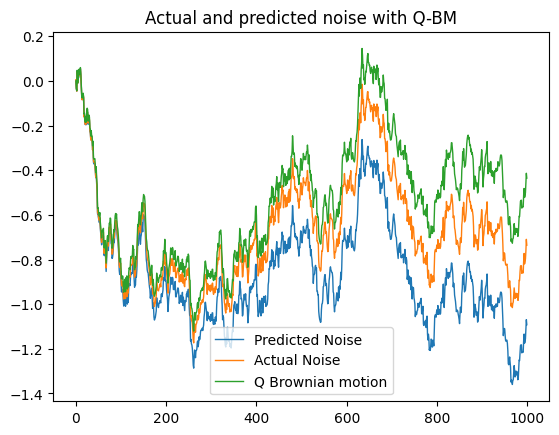

In [23]:
from models.p_brownian_motion import recover_p_noise
model = "matched_factor"
BP, dt, t = recover_p_noise(BQ, mu_pred1, sigma_pred, T)
plt.plot(BP, label="Predicted Noise", linewidth=1)
plt.plot(W, label="Actual Noise", linewidth=1)
plt.plot(BQ, label="Q Brownian motion", linewidth=1)
plt.title("Actual and predicted noise with Q-BM")
plt.legend()
plt.savefig(f"{model}_Actual and predicted noise with Q-BM.png", bbox_inches='tight', dpi=300)
plt.show()

### Drift from Method 1

MSE: 5.793e-08
μ(X) = 0.582411
σ(X) = 0.990875 + -0.193823*X^2 + -0.0495824*X^3
[CV best] alpha=0.000172, l1_ratio (rho)=0.40


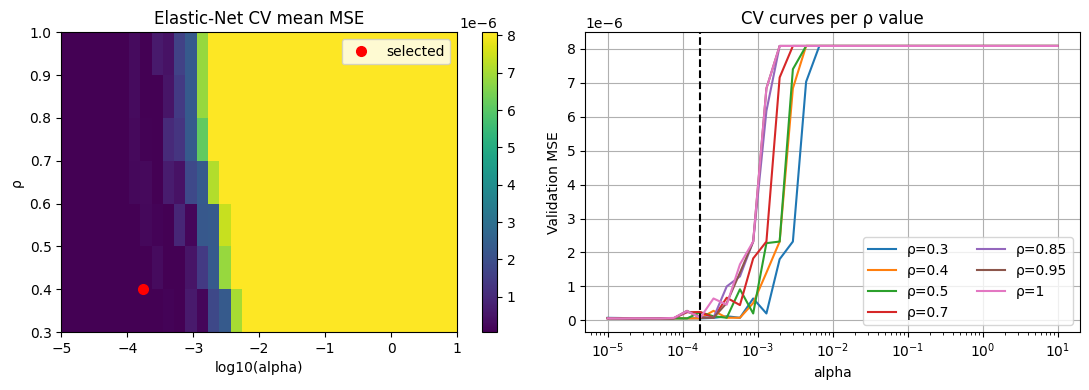

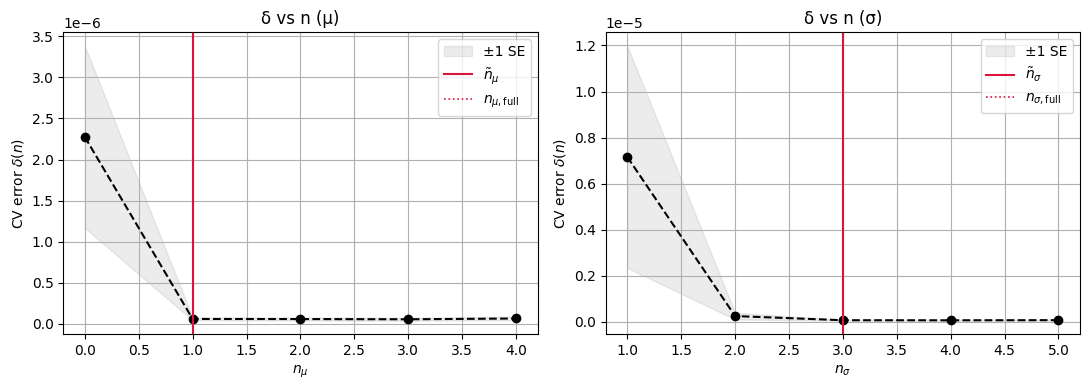

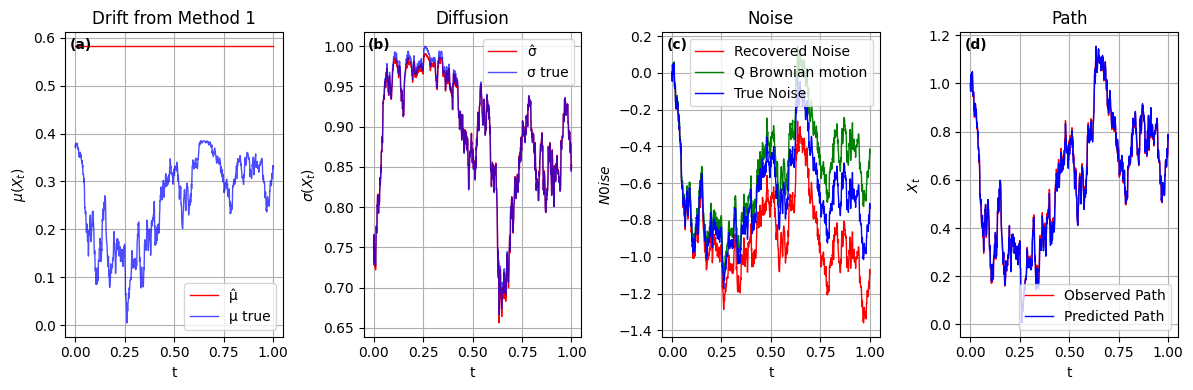

### Drift from Method 2

MSE: 5.136e-08
μ(X) = 0.503606
σ(X) = 0.990612 + -0.191901*X^2 + -0.0515233*X^3
[CV best] alpha=0.000172, l1_ratio (rho)=0.40


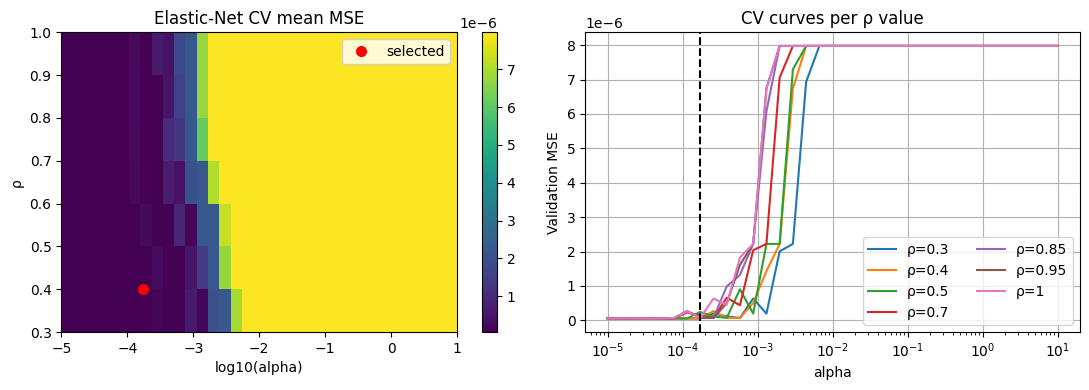

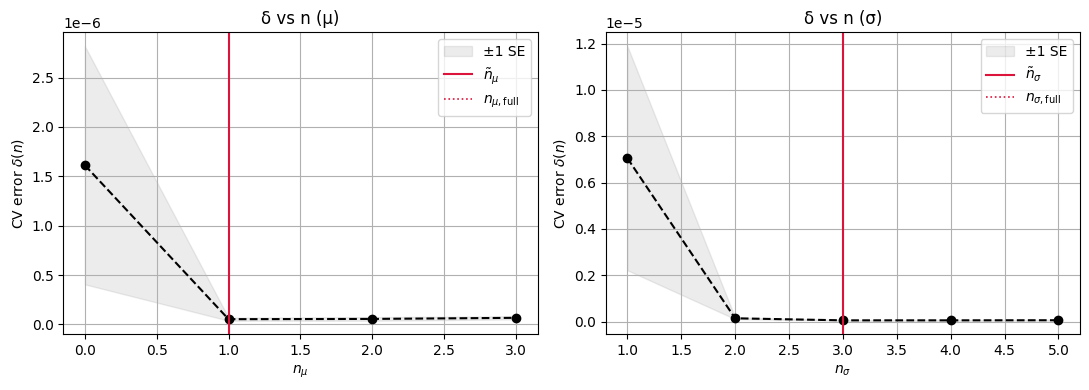

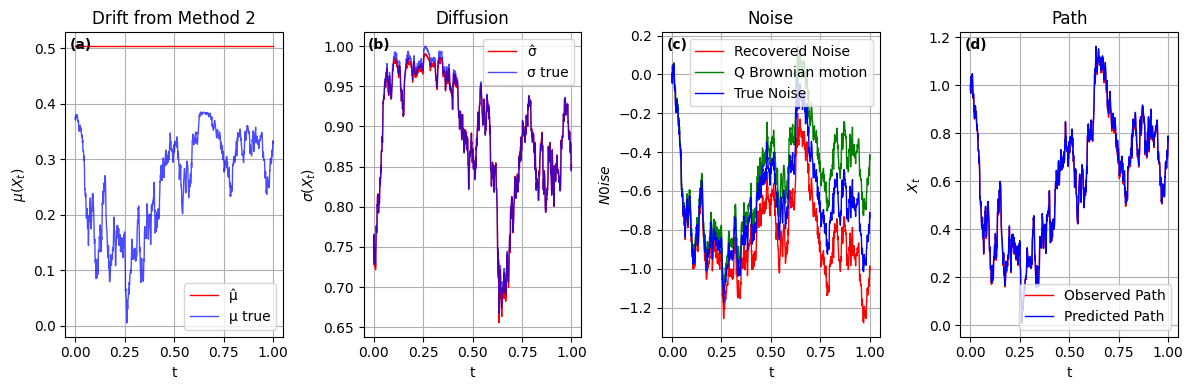

### Drift from ODE2

MSE: 5.518e-08
μ(X) = 0.620107*X
σ(X) = 0.990425 + -0.190636*X^2 + -0.052764*X^3
[CV best] alpha=0.000172, l1_ratio (rho)=0.40


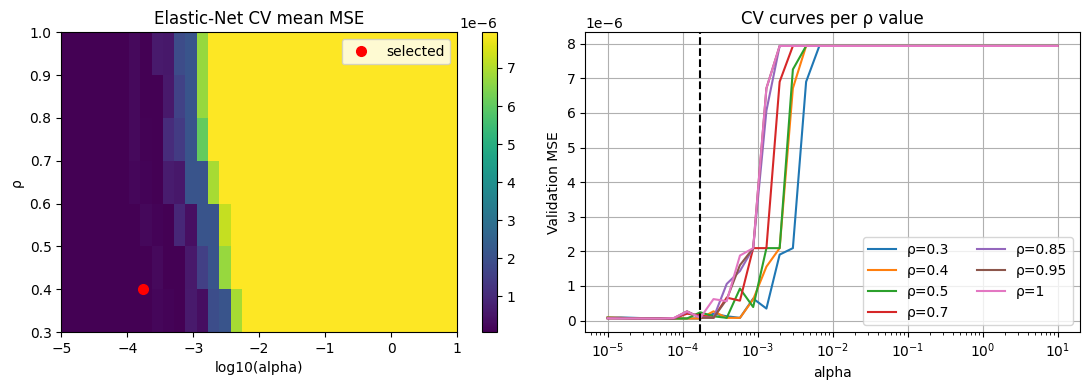

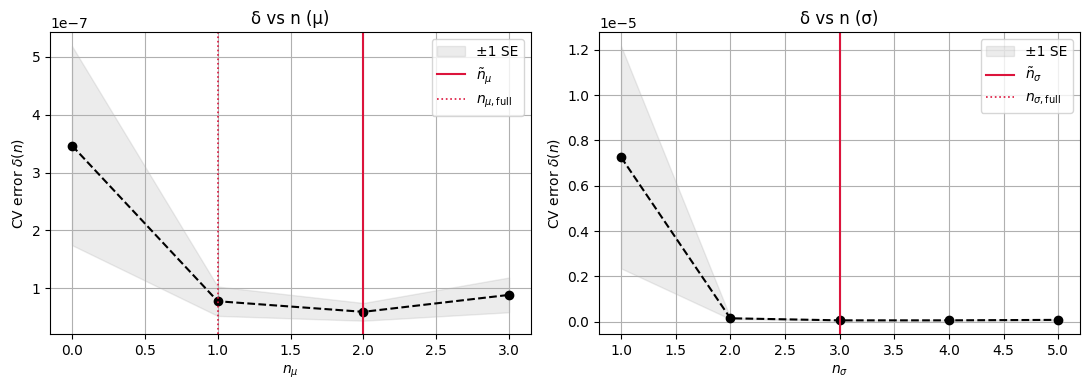

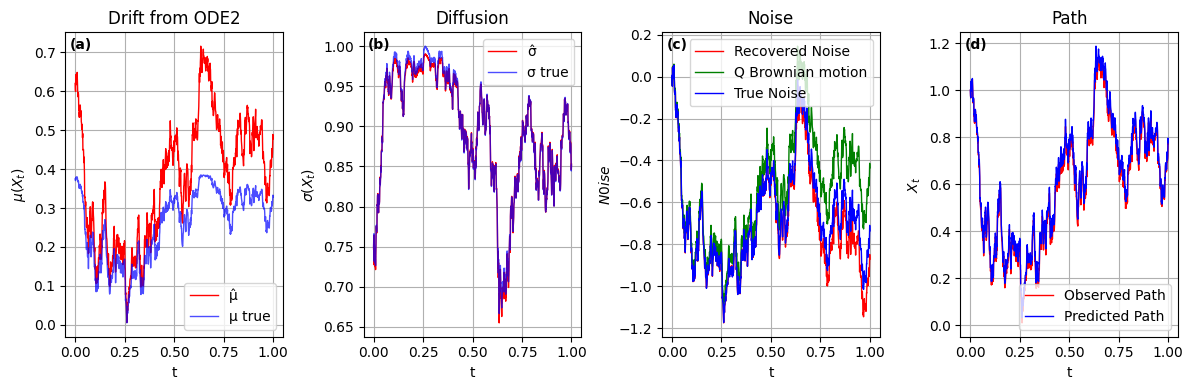

| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |
|---|---:|---:|---:|
| Method 1 | 0.220035 | 0.337044 | 0.00368088 |
| Method 2 | 0.165877 | 0.261963 | 0.0038079 |
| ODE2 | 0.0564329 | 0.133261 | 0.00389472 |

In [24]:
from models.stochastic_sindy import StochSINDy
from models.p_brownian_motion import recover_p_noise
from threadpoolctl import threadpool_limits
from IPython.display import Markdown, display
import json

recovered_drifts = {"Method 1": mu_pred1, "Method 2": mu_pred2, "ODE2": mu_pred11}
identifiers, noise_paths, ssisde_comparison, comparison_paths = {}, {}, {}, {}

for method_name, recovered_drift in recovered_drifts.items():
    method_key = method_name.lower().replace(" ", "_")
    BP_method, dt_method, _ = recover_p_noise(BQ, recovered_drift, sigma_pred, T)
    noise_paths[method_name] = BP_method
    identifier_method = StochSINDy(
        mu_deg=5, si_deg=5,
        pen="elasticnet",
        use_cv=True, k=7,
        alphas=np.geomspace(1e-5, 1e1, 35),
        rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0],
        use_1se=True,
    )
    with threadpool_limits(limits=1):
        identifier_method.fit(S, BP_method, dt_method)
    identifiers[method_name] = identifier_method
    output_prefix = f"{model}_{method_key}"
    display(Markdown(f"### Drift from {method_name}"))
    identifier_method.show()
    identifier_method.plot_cv(output_prefix=output_prefix)
    identifier_method.plot_size(count_bias=True, output_prefix=output_prefix)
    identifier_method.plot_results(
        S, BP_method, BQ, W, mu_true=mu_exact, si_true=sigma_exact,
        output_prefix=output_prefix, drift_title=f"Drift from {method_name}",
    )
    mu_fit = identifier_method.mu(S)
    sigma_fit = identifier_method.si(S)
    ssisde_comparison[method_name] = {
        "input_drift_rmse": float(np.sqrt(np.mean((recovered_drift - mu_exact)**2))),
        "noise_rmse": float(np.sqrt(np.mean((BP_method - W)**2))),
        "drift_rmse": float(np.sqrt(np.mean((mu_fit - mu_exact)**2))),
        "diffusion_rmse": float(np.sqrt(np.mean((sigma_fit - sigma_exact)**2))),
        "increment_mse": identifier_method.mse,
        "mu": identifier_method._fmt_poly(identifier_method.mu_c),
        "sigma": identifier_method._fmt_poly(identifier_method.si_c),
        "alpha": identifier_method.best_a,
        "rho": identifier_method.best_r,
    }
    comparison_paths[f"BP_{method_key}"] = BP_method
    comparison_paths[f"input_drift_{method_key}"] = recovered_drift
    comparison_paths[f"mu_fit_{method_key}"] = mu_fit
    comparison_paths[f"sigma_fit_{method_key}"] = sigma_fit

(RESULTS / "ssisde_comparison.json").write_text(json.dumps(ssisde_comparison, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / "ssisde_comparison_paths.npz", S=S, BQ=BQ, W=W,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    dt=dt, **comparison_paths)
rows = ["| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |",
        "|---|---:|---:|---:|"]
for method_name, values in ssisde_comparison.items():
    rows.append(f"| {method_name} | {values['noise_rmse']:.6g} | "
                f"{values['drift_rmse']:.6g} | {values['diffusion_rmse']:.6g} |")
display(Markdown("\n".join(rows)))
identifier = identifiers["Method 1"]


In [25]:
def rmse(estimate, actual):
    return float(np.sqrt(np.mean((np.asarray(estimate).ravel() - np.asarray(actual).ravel())**2)))

results = {
    'ssisde_comparison': ssisde_comparison,
    'experiment': 'Double-well potential: exactly linear ratio', 'coefficients': coefficients, 'workflow': 'Black-Scholes',
    'seed': seed, 'samples': N, 'T': T, 'X0': S0,
    'fine_dt': fine_dt, 'coarse_dt': dt, 'coarse_step': M,
    'sigma_settings': sigma_settings, 'sigma_squared_equation': sigma_equation,
    'sigma_rmse': rmse(sigma_pred_, sigma_exact_),
    'supplied_initial_drift': float(mu_0), 'supplied_initial_slope': float(lambda_0),
    'drift_rmse': {'Method 1': rmse(mu_pred1, mu_exact),
                   'Method 2': rmse(mu_pred2, mu_exact),
                   'ODE2': rmse(mu_pred11, mu_exact)},
    'noise_method': 'Method 1', 'noise_rmse': rmse(BP, W),
    'ssisde': {'mu': identifier._fmt_poly(identifier.mu_c),
               'sigma': identifier._fmt_poly(identifier.si_c),
               'drift_rmse': rmse(identifier.mu(S), mu_exact),
               'diffusion_rmse': rmse(identifier.si(S), sigma_exact),
               'increment_mse': identifier.mse,
               'alpha': identifier.best_a, 'rho': identifier.best_r},
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / 'paths.npz', S=S, W=W, BQ=BQ, BP=BP,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    mu_method1=mu_pred1, mu_method2=mu_pred2, mu_ode2=mu_pred11)
print(json.dumps(results, indent=2))

{
  "ssisde_comparison": {
    "Method 1": {
      "input_drift_rmse": 0.36934573221838524,
      "noise_rmse": 0.22003458824255015,
      "drift_rmse": 0.3370437552681939,
      "diffusion_rmse": 0.0036808821191565426,
      "increment_mse": 5.7931169964416985e-08,
      "mu": "0.582411",
      "sigma": "0.990875 + -0.193823*X^2 + -0.0495824*X^3",
      "alpha": 0.00017190722018585745,
      "rho": 0.4
    },
    "Method 2": {
      "input_drift_rmse": 0.27636089482639986,
      "noise_rmse": 0.165877477020555,
      "drift_rmse": 0.26196257444266025,
      "diffusion_rmse": 0.0038079006905435498,
      "increment_mse": 5.136079128563112e-08,
      "mu": "0.503606",
      "sigma": "0.990612 + -0.191901*X^2 + -0.0515233*X^3",
      "alpha": 0.00017190722018585745,
      "rho": 0.4
    },
    "ODE2": {
      "input_drift_rmse": 0.1643516001666189,
      "noise_rmse": 0.05643287409777363,
      "drift_rmse": 0.13326129465468617,
      "diffusion_rmse": 0.0038947156876379947,
      "incre

## Curvature and coefficient comparison

For $\mu(x)=ax-bx^3$ and $\sigma(x)=c+dx^2$,
$$\left(\frac{\mu}{\sigma}\right)''=
\frac{2x(ad+bc)(dx^2-3c)}{(c+dx^2)^3}.$$

This expression is used only to assess the chosen problem. Recovery still uses the existing estimated diffusion and finite-difference derivatives. Relative drift error is RMSE divided by the RMS of the actual drift. All methods receive the known initial drift; ODE2 also receives the known initial slope.

The JSON records next to this notebook contain the coefficient trials and separate checks using seeds 7 and 11. To repeat that study from the repository root:
```bash
.venv/bin/python scripts/compare_double_well_coefficients.py
.venv/bin/python scripts/compare_double_well_coefficients.py --cases original cubic_001 lower_noise matched_factor --seeds 7 11
```


In [26]:
curvature = (2*S_*(coefficients['a']*coefficients['d'] + coefficients['b']*coefficients['c'])
             *(coefficients['d']*S_**2 - 3*coefficients['c'])
             /(coefficients['c'] + coefficients['d']*S_**2)**3)
print(f"Observed state range: [{S_.min():.6f}, {S_.max():.6f}]")
print(f"Smallest actual diffusion on the path: {sigma_exact_.min():.6f}")
print(f"RMS of (mu/sigma)'': {np.sqrt(np.mean(curvature**2)):.6f}")
print(f"Maximum absolute (mu/sigma)'': {np.max(np.abs(curvature)):.6f}")
print(f"ODE2 relative drift RMSE: {rmse(mu_pred11, mu_exact)/np.sqrt(np.mean(mu_exact**2)):.2%}")

from IPython.display import Markdown, display
records = [json.loads(path.read_text()) for path in Path.cwd().glob('*_seed*.json')]
rows = ["| Case | Seed | a, b, c, d | Curvature RMS | ODE2 RMSE | Relative RMSE |",
        "|---|---:|---|---:|---:|---:|"]
for row in sorted(records, key=lambda r: (r['seed'], r['case'])):
    values = ', '.join(str(row['coefficients'][key]) for key in ['a', 'b', 'c', 'd'])
    if row.get('status') == 'failed':
        rows.append(f"| {row['case']} | {row['seed']} | {values} | - | Diffusion fit failed | - |")
        continue
    rows.append(f"| {row['case']} | {row['seed']} | {values} | {row['curvature_rms']:.6f} | "
                f"{row['drift_rmse']['ODE2']:.6f} | {row['ode2_relative_rmse']:.2%} |")
display(Markdown('\n'.join(rows)))


Observed state range: [-0.006314, 1.158504]
Smallest actual diffusion on the path: 0.664467
RMS of (mu/sigma)'': 0.000000
Maximum absolute (mu/sigma)'': 0.000000
ODE2 relative drift RMSE: 60.21%


| Case | Seed | a, b, c, d | Curvature RMS | ODE2 RMSE | Relative RMSE |
|---|---:|---|---:|---:|---:|
| cubic_001 | 3 | 0.5, 0.01, 1.0, 0.01 | 0.043851 | 0.010529 | 4.29% |
| cubic_005 | 3 | 0.5, 0.05, 1.0, 0.01 | 0.159697 | 0.052970 | 22.68% |
| cubic_010 | 3 | 0.5, 0.1, 1.0, 0.05 | 0.324334 | 0.111994 | 53.04% |
| lower_noise | 3 | 0.5, 0.01, 0.5, 0.01 | 0.197479 | 0.003582 | 0.84% |
| matched_factor | 3 | 0.5, 0.125, 1.0, -0.25 | 0.000000 | 0.164352 | 60.21% |
| near_matched | 3 | 0.5, 0.125, 1.0, -0.24 | 0.037115 | 0.162288 | 59.99% |
| original | 3 | 0.5, 1.0, 1.0, 0.25 | 1.792701 | 1.038716 | 897.89% |
| wells_at_one | 3 | 0.05, 0.05, 0.3, 0.01 | 0.772601 | 0.007165 | 50.24% |
| cubic_001 | 7 | 0.5, 0.01, 1.0, 0.01 | 0.053313 | 0.020724 | 6.95% |
| lower_noise | 7 | 0.5, 0.01, 0.5, 0.01 | 0.211461 | 0.000581 | 0.13% |
| matched_factor | 7 | 0.5, 0.125, 1.0, -0.25 | 0.000000 | 0.696116 | 214.22% |
| original | 7 | 0.5, 1.0, 1.0, 0.25 | 2.182421 | 0.844152 | 764.59% |
| cubic_001 | 11 | 0.5, 0.01, 1.0, 0.01 | 0.184306 | 0.437719 | 38.93% |
| lower_noise | 11 | 0.5, 0.01, 0.5, 0.01 | 0.359178 | 0.154430 | 16.31% |
| matched_factor | 11 | 0.5, 0.125, 1.0, -0.25 | 0.000000 | 0.316465 | 138.23% |
| original | 11 | 0.5, 1.0, 1.0, 0.25 | - | Diffusion fit failed | - |